---
## **0. 준비**
---

In [ ]:
%%html
<style>
    body {
        /* change --vscode-font-family if it's different on your system */
        --vscode-font-family: "SeoulNamsanC";
    }
</style>

In [96]:
from langchain_openai import ChatOpenAI
from langchain_google_genai import GoogleGenerativeAI

from langgraph.graph import StateGraph, START, END                          
from typing import TypedDict                                                
from langchain_classic.output_parsers import EnumOutputParser
from typing import Annotated, Optional, Union
from langchain_core.runnables.config import RunnableConfig

In [2]:
from langchain_core.messages import SystemMessage, HumanMessage, AIMessage
from IPython.display import display, Markdown

In [3]:
import config
config.set_environment()

---
## **LangGraph의 기본 원리**
---


### **(매우중요) 큰 그림 복습: 메시지·템플릿·체인·상태·그래프는 어떻게 연결되는가?**

- `invoke()`라는 같은 메서드를 사용하면서 입력이 메시지에서 딕셔너리로 바뀌는 이유는 **호출하는 객체가 달라졌기 때문**이다.
- 앞 장의 모델 호출을 이번 장에서는 더 큰 워크플로의 부품으로 사용한다.

채용 공고를 받아 지원서를 작성하는 프로그램을 기준으로 전체 구조를 연결해 보자.

**1. 메시지: 모델에게 전달할 대화의 형식**

```python
messages = [
    SystemMessage(content="너는 취업 상담사다."),
    HumanMessage(content="이 채용 공고를 분석해줘."),
]
# response = llm.invoke(messages)
```

| 메시지 | 역할 |
|---|---|
| `SystemMessage` | 모델의 역할과 행동 지침 |
| `HumanMessage` | 사용자의 질문이나 자료 |
| `AIMessage` | 모델의 답변 |

`ChatOpenAI` 같은 채팅 모델을 호출하면 `AIMessage`를 받는다. 답변 텍스트는 `response.text`로 확인한다. 메시지는 그래프를 배우기 전과 후 모두 모델과 소통하는 데 쓰인다.

<hr style="border:0;border-top:1.5px dashed gray;">

**2. 템플릿: 메시지나 문자열을 반복해서 만들기 위한 틀**

공고가 바뀔 때마다 메시지를 새로 작성하지 않도록 빈칸을 둔다.

```python
from langchain_core.prompts import ChatPromptTemplate

template = ChatPromptTemplate.from_messages([
    ("system", "너는 취업 상담사다."),
    ("human", "다음 채용 공고를 분석해줘:\n{job_description}"),
])

prompt_value = template.invoke({
    "job_description": "파이썬 개발자를 모집합니다."
})
messages = prompt_value.to_messages()
# response = llm.invoke(messages)
```

템플릿의 `invoke()`는 빈칸을 채우며 모델을 호출하지 않는다. `ChatPromptTemplate`은 역할별 메시지를 담은 `ChatPromptValue`를 만들고, `PromptTemplate`은 문자열 기반의 `StringPromptValue`를 만든다. 후자를 채팅 모델에 전달하면 일반적으로 사용자 메시지 하나로 변환된다.

**템플릿을 사용해도 메시지가 사라지는 것은 아니다. 메시지를 만드는 일을 템플릿이 맡게 된 것이다.**

<hr style="border:0;border-top:1.5px dashed gray;">

**3. 체인과 출력 파서: 입력 준비부터 응답 변환까지 연결**

```python
from langchain_core.output_parsers import StrOutputParser

# llm이 준비되어 있을 때 구성하는 예시
# chain = template | llm | StrOutputParser()
# result = chain.invoke({"job_description": "파이썬 개발자를 모집합니다."})
```

```text
공고를 담은 딕셔너리
    ↓ template: 빈칸 채우기
완성된 메시지를 담은 프롬프트 값
    ↓ llm: 모델 호출
AIMessage
    ↓ StrOutputParser: 텍스트 추출
답변 문자열
```

출력 파싱 단원에서 템플릿이 다시 등장하는 이유는 **입력을 준비하는 템플릿과 출력을 정리하는 파서를 하나의 호출 흐름으로 연결하기 때문**이다. `StrOutputParser`는 텍스트를 추출하고, 다른 구조화 파서는 지원하는 규칙에 따라 JSON이나 데이터 객체 등을 다룬다. 문자열 추출만으로 구조화 데이터 검증까지 이루어지는 것은 아니다.

<hr style="border:0;border-top:1.5px dashed gray;">

**4. 상태: 전체 작업에서 공유할 입력과 중간 결과**

그래프에서는 `공고 분석 → 적합 여부 판단 → 지원서 작성`처럼 여러 단계를 실행한다. 단계들이 사용할 자료와 결과를 상태에 보관한다.

```python
class JobApplicationState(TypedDict):
    job_description: str
    is_suitable: bool
    application: str
```

위 클래스는 스키마다. 실행 중 실제 상태는 다음과 같은 딕셔너리다.

```python
{
    "job_description": "파이썬 개발자를 모집합니다.",
    "is_suitable": True,
    "application": "지원서 내용...",
}
```

모든 키가 처음부터 들어 있어야 하는 것은 아니다. 초기 입력에는 공고만 있고, 이후 노드들이 판단 결과와 지원서를 채울 수 있다. 스키마 선언만으로 값이 자동 생성되지는 않는다.

**메시지는 모델에 보낼 대화 형식이고, 상태는 워크플로 전체의 작업 자료다. 상태 안에 메시지 목록도 넣을 수 있다.**

<hr style="border:0;border-top:1.5px dashed gray;">

**5. 노드 안에서 앞 장의 체인을 사용한다**

```python
application_template = ChatPromptTemplate.from_messages([
    ("system", "너는 지원서 작성 도우미다."),
    ("human", "다음 공고에 맞는 짧은 지원서를 작성해줘:\n{job_description}"),
])

# application_chain = application_template | llm | StrOutputParser()

# 아래는 application_chain을 만든 뒤 사용할 노드 함수의 예시다.
def generate_application(state):
    application = application_chain.invoke({
        "job_description": state["job_description"]
    })
    return {"application": application}
```

노드는 상태에서 필요한 공고를 꺼내 체인에 전달하고, 답변 문자열을 `application`의 업데이트로 반환한다. 이 코드 블록은 역할 설명용이며, 노트북의 기존 노드를 교체할 필요는 없다.

```text
graph.invoke(초기 상태)
    ↓
공고 분석 노드 → 조건부 에지가 다음 경로 선택
    ├─ 부적합 → 종료
    └─ 적합 → 지원서 작성 노드
                  │
                  ├─ 상태에서 공고 추출
                  ├─ 템플릿으로 메시지 구성
                  ├─ LLM 호출 → AIMessage
                  ├─ 출력 파서 → 문자열
                  └─ {"application": 문자열} 반환
                          ↓
                   상태 업데이트 → 종료
                          ↓
                     최종 상태 반환
```

**LangGraph 노드 안에 LangChain 체인이 들어갈 수 있다.** 모든 노드가 모델을 호출해야 하는 것은 아니다. 앞서 실습한 `len(...) > 100` 같은 일반 파이썬 계산도 노드가 된다.

<hr style="border:0;border-top:1.5px dashed gray;">

**6. 메시지 상태: 상태에 대화 메시지 목록을 포함하는 방식**

```python
from langgraph.graph import MessagesState

class ApplicationState(MessagesState):
    job_description: str
    application: str
```

```text
상태
├─ job_description: 공고
├─ application: 지원서
└─ messages: 대화 메시지 목록 (MessagesState에서 상속)
```

**메시지 상태를 쓰는 노드에서는 템플릿 없이 이미 완성된 메시지를 바로 전달할 수도 있다.**

```python
def chat_node(state):
    response = llm.invoke(state["messages"])
    return {"messages": [response]}
```

```text
graph.invoke({"messages": [...]})
    ↓ 노드가 상태에서 메시지를 꺼냄
llm.invoke(state["messages"])
    ↓ 모델 응답
{"messages": [새 AIMessage]} 반환
    ↓ add_messages 리듀서
기존 메시지와 새 메시지 병합
```

`MessagesState`는 `messages`와 `add_messages` 설정을 기본 제공한다. 새로운 ID의 메시지는 추가하고, 같은 ID의 메시지는 교체한다. 상태에 메시지가 있다고 모델이 자동으로 읽는 것은 아니므로 노드에서 명시적으로 전달해야 한다. 실행 간 대화 보존에는 체크포인터 등의 설정이 별도로 필요하다.

**템플릿과 메시지 상태는 함께 사용할 수도 있다.** 템플릿은 보낼 대화를 구성하는 도구이고, 메시지 상태는 그 대화를 보관·갱신하는 공간이다. 템플릿에 대화 기록을 넣고 싶다면 `MessagesPlaceholder` 같은 장치를 사용할 수 있으며, 그 사용법은 이후에 학습한다.

<hr style="border:0;border-top:1.5px dashed gray;">

**7. `invoke()`는 객체마다 입력과 결과가 다르다**

| 호출 대상 | 입력 | 결과 |
|---|---|---|
| `template.invoke(...)` | 빈칸을 채울 값 | 완성된 프롬프트 값 |
| `llm.invoke(...)` | 메시지·문자열·프롬프트 값 | 채팅 모델의 경우 `AIMessage` |
| `chain.invoke(...)` | 첫 단계가 요구하는 입력 | 마지막 단계의 결과 |
| `graph.invoke(...)` | 초기 상태 또는 상태 업데이트 | 출력 스키마에 따른 최종 결과. 이 실습에서는 상태 딕셔너리 |

`chain.invoke()`가 항상 딕셔너리를 받아 문자열을 반환하는 것은 아니다. **첫 단계가 입력을 정하고, 마지막 단계가 출력을 정한다.** 그래프의 `invoke()`가 상태를 받는 것과 노드 안 모델의 `invoke()`가 메시지를 받는 것은 서로 다른 층의 호출이므로 모순되지 않는다.

**개념을 연결해서 읽기**

> **상태**에 작업 자료를 담는다. **그래프의 에지**가 다음에 실행할 **노드**를 결정한다. 노드는 상태에서 자료를 꺼내고, **템플릿**은 이를 모델에 보낼 **메시지**로 구성한다. **LLM**이 답변하면 **출력 파서**가 결과를 정리한다. 노드가 업데이트를 반환하면 **리듀서**가 상태에 반영한다.

이 흐름의 모든 부품을 매번 사용할 필요는 없다. 단순 노드는 파이썬 계산만 수행하고, 이미 메시지가 준비된 경우에는 템플릿을 생략할 수 있다. 전체 구조에서 각 부품이 맡는 역할을 구분하는 것이 핵심이다.


---
### **제어된 출력 생성**
- 복잡한 워크플로를 개발할 때 **가장 핵심적인 과제는 LLM이 정해진 구조에 맞는 출력을 생성하도록 만드는 것**
    - 예) API 호출용 JSON, XML 생성, 텍스트에서 특정 속성 추출, CSV 테이블 생성 등
    - 이를 구현하는 방법은 다양하며, 5장에서 자세히 다룰 것
    - **견고한 출력 파싱과 효과적인 오류 처리가 필수적임**

<hr style="border:0;border-top:1.5px dashed gray;">

#### **출력 파싱**
- 출력 파싱은 자연어 응답이 아닌 구조화된 데이터가 필요한 대규모 워크플로에서 LLM을 통합할때 필수
- 이는 프롬프트에 명확한 지침을 포함하고 결과를 파싱하는 방식으로 구현
- 아래 예시:
    - 목적 : 주니어 자바 프로그래머에 대한 특정 직무 설명이 적합한지 파이프라인에서 평가하고, LLM의 판단을 기반으로 채용공고 게시 여부를 결정

In [92]:
# 예시: 채용 공고 게시 여부를 결정 

from langchain_openai import ChatOpenAI
from langchain_core.prompts import PromptTemplate

llm = ChatOpenAI(model = "gpt-6-luna", use_responses_api=True)

job_description : str = """백엔드 개발 경력 7년 이상의 자바 소프트웨어 엔지니어를 모집합니다. 지원자는 분산 시스템, 마이크로서비스 아키텍쳐, 성능 튜닝 및 대규모 시스템 설계에 대한 심도 있는 지식을 보유해야 합니다..."""

prompt_template = (
    "전달하는 JD를 보고 주니어 자바에 적당한지 결정해봐."
    "\nJob Description:\n{job_description}\n"
)

result = llm.invoke(prompt_template.format(job_description=job_description))

# 출력
print("\n[답변]")
display(Markdown(result.text) or "답변 텍스트 없음: 토큰 상한과 응답 상태를 확인하세요.")

print("\n[추론 요약 — 내부 사고 원문이 아닙니다]")                     

summaries = [
    block["reasoning"]                                                 
    for block in result.content_blocks                               
    if block.get("type") == "reasoning" and block.get("reasoning")]    
print("\n".join(summaries) if summaries else                            
        "이 응답에는 공개된 추론 요약이 없습니다.")                       


[답변]


이 JD는 **주니어 자바 개발자에게 적합하지 않습니다.**

- **백엔드 경력 7년 이상**을 명시해 시니어급을 찾고 있습니다.
- 분산 시스템, 마이크로서비스, 성능 튜닝, 대규모 시스템 설계에 대한 **심도 있는 실무 경험**을 요구합니다.

따라서 주니어라면 요구 경력과 기술 깊이 모두에서 차이가 큽니다. 경력 요건이 유연하다는 안내가 따로 없다면, **주니어/신입 또는 경력 1~3년 대상 공고**를 찾는 편이 좋습니다.


[추론 요약 — 내부 사고 원문이 아닙니다]
이 응답에는 공개된 추론 요약이 없습니다.


> - LLM의 출력은 자유로운 형식의 텍스트로 생성되기 때문에 파이프라인 후속 단계에서 파싱이나 해석이 어려울 수 있음
> - 프롬프트에 구체적인 지시 사항을 넣어 출력을 제어하고 후속 단계를 고려할 수 있음

In [93]:
prompt_template_enum = (
    "전달하는 JD를 보고 주니어 자바에 적당한지 결정해봐."
    "\nJob Description:\n{job_description}\n"
    "\nAnswer only YES or NO."
)

result_enum = llm.invoke(prompt_template_enum.format(job_description=job_description))
display(Markdown(result_enum.text))

NO

- **OutputParser**
    - LangChain은 다양한 OutputParser를 제공
    - 이들은 **LLM이 생성한 출력을 가져와 원하는 형식(필요한 경우 스키마를 검사하면서)으로 파싱 시도**
    - **List, CSV, 열거형(enum), DataFrame, Pydantic 모델, JSON, XML** 등이 그 대상
    - 각 파서는 `BaseGenerationOuputParser` 인터페이스를 구현
        - Runnable 인터페이스를 확장하며 추가적으로 `parse_result` 메서드를 포함
        - 해당 메서드를 통해 LLM의 출력을 정형 데이터로 안전하게 변환

In [94]:
# 출력을 열거형(Enum)으로 파싱하는 예제

from enum import Enum                                                       #정해진 이름과 값을 갖는 선택지 묶음인 Enum
from langchain_classic.output_parsers import EnumOutputParser               #텍스트를 지정한 Enum의 멤버로 변환하는 LangChain 출력 파서 클래스
from langchain_core.messages import HumanMessage

    # 적합 여부를 두 선택지로 나타내는 사용자 정의 Enum 타입을 만듭니다.
class IsSuitableJobEnum(Enum):
    YES = "YES"                                                             #멤버 이름은 YES, 실제 문자열 값도 "YES", 서로 다른 개념이지만 여기서는 같게 지정
    NO = "NO"                                                               #IsSuitableJobEnum.NO로 이 멤버에 접근. 멤버 자체는 문자열 "NO"와 다름

    # (중요) 어떤 Enum으로 변환할지 위에서 만든 클래스 자체를 전달, IsSuitableJobEnum()을 호출하는 것이 아님
parser = EnumOutputParser(enum=IsSuitableJobEnum)                           #내부적으로 문자열 양끝 공백과 줄바꿈을 제거한 뒤, 해당 값의 Enum 멤버를 찾아 반환

    # 아래는 정상 동작을 확인하는 작은 예제들
    # assert는 비교가 True면 조용히 통과하고 False면 AssertionError를 발생시키는 검산 문법.
assert parser.invoke("NO") == IsSuitableJobEnum.NO                          #"NO"를 파싱한 결과가 NO 멤버인지 검사, 결과는 문자열이나 bool이 아니라 Enum 멤버임.
assert parser.invoke("YES\n") == IsSuitableJobEnum.YES                      #해당 Parser는 문자열 끝의 \n(줄바꿈)은 제거하므로 "YES"와 같은 결과가 나오는지 검사.
assert parser.invoke(" YES \n") == IsSuitableJobEnum.YES                    #양끝의 공백과 줄바꿈을 제거한 뒤 YES 멤버로 변환하는지 검사합니다.
assert parser.invoke(HumanMessage(content="YES")) == IsSuitableJobEnum.YES  #HumanMessage의 텍스트 내용을 꺼내 같은 규칙으로 파싱하는지 검사, 실제 LLM 응답은 보통 AIMessage이지만, 여기서는 메시지 입력도 처리한다는 것을 보여줌


---
#### **14번 셀 학습 노트: 파서는 무엇을 하는가?**
- **파싱(parsing)** 은 받은 데이터를 규칙에 맞게 읽어 프로그램에서 사용할 형태로 변환하는 작업이다. 
- 여기서 `EnumOutputParser`는 적합 여부를 새로 판단하지 않는다. **이미 받은 답변이 허용된 선택지인지 검사하고, 문자열을 Enum 멤버로 변환**한다.

```text
LLM의 답변 문자열 또는 메시지
    ↓ 텍스트 추출 및 양끝 공백 제거
"YES" 또는 "NO"인지 확인
    ↓ 일치하는 Enum 멤버로 변환
IsSuitableJobEnum.YES 또는 IsSuitableJobEnum.NO
```
<hr style="border:0;border-top:1.5px dashed gray;">

**1. Enum은 선택지를 명확하게 정의한다**

```python
class IsSuitableJobEnum(Enum):
    YES = "YES"
    NO = "NO"
```

| 표현 | 의미 |
|---|---|
| `IsSuitableJobEnum` | 사용자 정의 Enum 타입 |
| `IsSuitableJobEnum.YES` | YES 선택지를 나타내는 Enum 멤버 |
| `IsSuitableJobEnum.YES.name` | 멤버 이름인 문자열 `"YES"` |
| `IsSuitableJobEnum.YES.value` | 멤버에 저장된 값인 문자열 `"YES"` |

멤버 이름과 값은 다르게 정할 수도 있다. 이 파서는 **멤버의 문자열 값(`.value`)** 과 모델 답변을 맞춘다. `IsSuitableJobEnum.YES` 자체는 `"YES"`나 `True`가 아니다.

<hr style="border:0;border-top:1.5px dashed gray;">

**2. 파서 생성과 호출은 별개다**

```python
parser = EnumOutputParser(enum=IsSuitableJobEnum)
decision = parser.invoke(" YES \n")
```

**첫 줄은 변환 규칙을 가진 객체를 만들고**, 둘째 줄은 실제 입력에 그 규칙을 적용한다. 이 `invoke()`는 **파서를 실행하는 호출**이다. 모델의 `invoke()`와 이름은 같지만 모델에게 질문하는 작업은 아니다.

현재 구현의 핵심은 다음과 같다.

```python
# 이해를 위한 핵심 동작 요약
cleaned_text = " YES \n".strip()
decision = IsSuitableJobEnum(cleaned_text)
```

`strip()`은 문자열 양끝의 공백·줄바꿈 등을 제거한다. `IsSuitableJobEnum("YES")`는 해당 값을 가진 YES 멤버를 찾는다. 일치하는 값이 없으면 파서는 `OutputParserException`을 발생시킨다.

<hr style="border:0;border-top:1.5px dashed gray;">

**3. 네 개의 assert는 정상 동작을 확인하는 작은 예제다**

| 입력 | 결과 | 이유 |
|---|---|---|
| `"NO"` | `IsSuitableJobEnum.NO` | 허용된 값과 일치 |
| `"YES\n"` | `IsSuitableJobEnum.YES` | 끝 줄바꿈 제거 |
| `" YES \n"` | `IsSuitableJobEnum.YES` | 양끝 공백·줄바꿈 제거 |
| `HumanMessage(content="YES")` | `IsSuitableJobEnum.YES` | 메시지의 텍스트 내용을 파싱 |

모든 `assert`가 통과해도 별도 출력은 없다. 출력해서 보고 싶다면 새 셀에서 다음만 실행해도 된다. API 호출은 발생하지 않는다.

```python
decision = parser.invoke(" YES \n")
print(decision)        # IsSuitableJobEnum.YES
print(decision.name)   # YES
print(decision.value)  # YES
print(type(decision))  # <enum 'IsSuitableJobEnum'>
```
<hr style="border:0;border-top:1.5px dashed gray;">

**4. 자동으로 무엇이든 고쳐 주지는 않는다**

`"yes"`, `"Yes"`, `"YES."`, `"YES, 적합합니다"`는 양끝 공백을 제거해도 `"YES"`와 다르므로 현재 파서에서는 실패한다. 앞 셀의 지시가 `Answer only Yes or No.`라면, 모델이 대소문자를 그대로 따라 `Yes`라고 답할 수 있다. 이 Enum에 맞추려면 지시도 `Answer only YES or NO.`처럼 일치시키는 것이 좋다. 그래도 모델이 형식을 어길 수 있으므로 파싱 오류에 대한 처리는 별도로 필요하다.

메시지를 입력으로 지원한다고 해서 이미지·음성 등 모든 생성 결과를 이 파서가 이해하는 것은 아니다. 이 실습은 **텍스트 답변을 정해진 선택지로 변환**하는 경우다.

<hr style="border:0;border-top:1.5px dashed gray;">

**5. 그래프에서는 조건 분기에 활용할 수 있다**

```python
# 앞에서 모델 응답을 result_enum에 저장했다면 별도 모델 호출 없이 파싱 가능
# decision = parser.invoke(result_enum)
# is_suitable = decision == IsSuitableJobEnum.YES
# return {"is_suitable": is_suitable}  # 노드 함수 안에서 상태 업데이트로 반환
```

`bool(decision)`으로 YES/NO를 판단하면 안 된다. **이 일반 Enum에서는 YES와 NO 멤버 모두 참으로 평가되므로 반드시 YES 멤버와 비교**한다.

체인으로 구성하면 `프롬프트 템플릿 → LLM → EnumOutputParser → Enum 멤버`가 된다. 파서는 답변 형식을 검사할 뿐, 모델의 적합성 판단이 사실인지까지 검증하지 않는다.

In [ ]:
# 이제 앞서 살펴본 모든 요소를 하나의 체인으로 통합

chain = llm | parser
result = chain.invoke(prompt_template_enum.format(job_description=job_description))
print(result.value)

NO


In [ ]:
# 이제 이 체인을 LangGraph 워크플로의 일부로 만들어보자.

class JobApplicationState(TypedDict):
    job_description: str
    is_suitable: IsSuitableJobEnum
    application: str

analyze_chain = llm | parser

def analyze_job_description(state):
    prompt = prompt_template_enum.format(job_description=state["job_description"])
    result = analyze_chain.invoke(prompt)
    return {"is_suitable": result}

def is_suitable_condition(state: JobApplicationState):
    return state["is_suitable"] == IsSuitableJobEnum.YES

def generate_application(state):
    print("...generating application...")
    return {"application": "some_fake_application", "actions": ["action2"]}

builder = StateGraph(JobApplicationState)
builder.add_node("analyze_job_description", analyze_job_description)
builder.add_node("generate_application", generate_application)
builder.add_edge(START, "analyze_job_description")
builder.add_conditional_edges(
    "analyze_job_description", is_suitable_condition,
    {True: "generate_application", False: END})
builder.add_edge("generate_application", END)
graph = builder.compile()


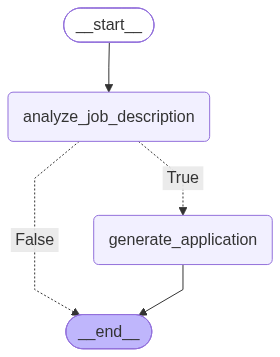

In [98]:
from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

> - 새로 구축한 체인은 이제 analyze_job_description 노드를 표현하는 파이썬 함수의 일부
> - 조건부 에지 함수(condiational edge function)는 더 이상 문자열을 반환하지 않지만, **add_conditional_edges 함수에 반환값과 목적지 에지의 매핑을 추가함** -> 이는 워크플로 분기(branching)를 구현하는 한 가지 예시임

<hr style="border:0;border-top:1.5px dashed gray;">

#### **오류 처리(일단 skip)**

---
## **프롬프트 엔지니어링(일단 skip)**
---

---
## **제한된 컨택스트 창으로 작업하기(일단 skip)**
---

---
## **메모리 메커니즘의 이해(일단 skip)**
---